/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


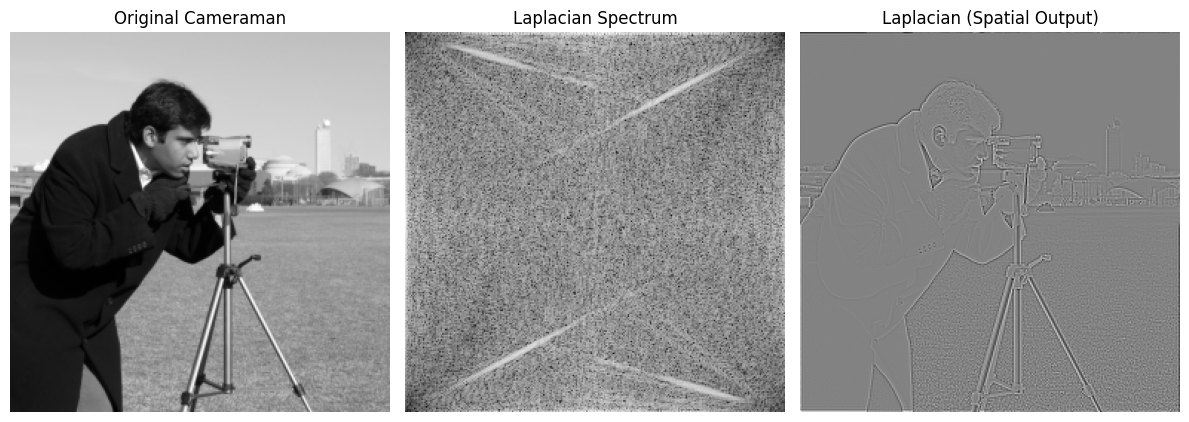

In [ ]:
Name : Nawaf Mohammed Alghamdi
ID: 2240007352

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256)) # Resize for faster FFT (optional)

# Get image size
M, N = image.shape

# Generate frequency grid (centered)
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Compute Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.show()

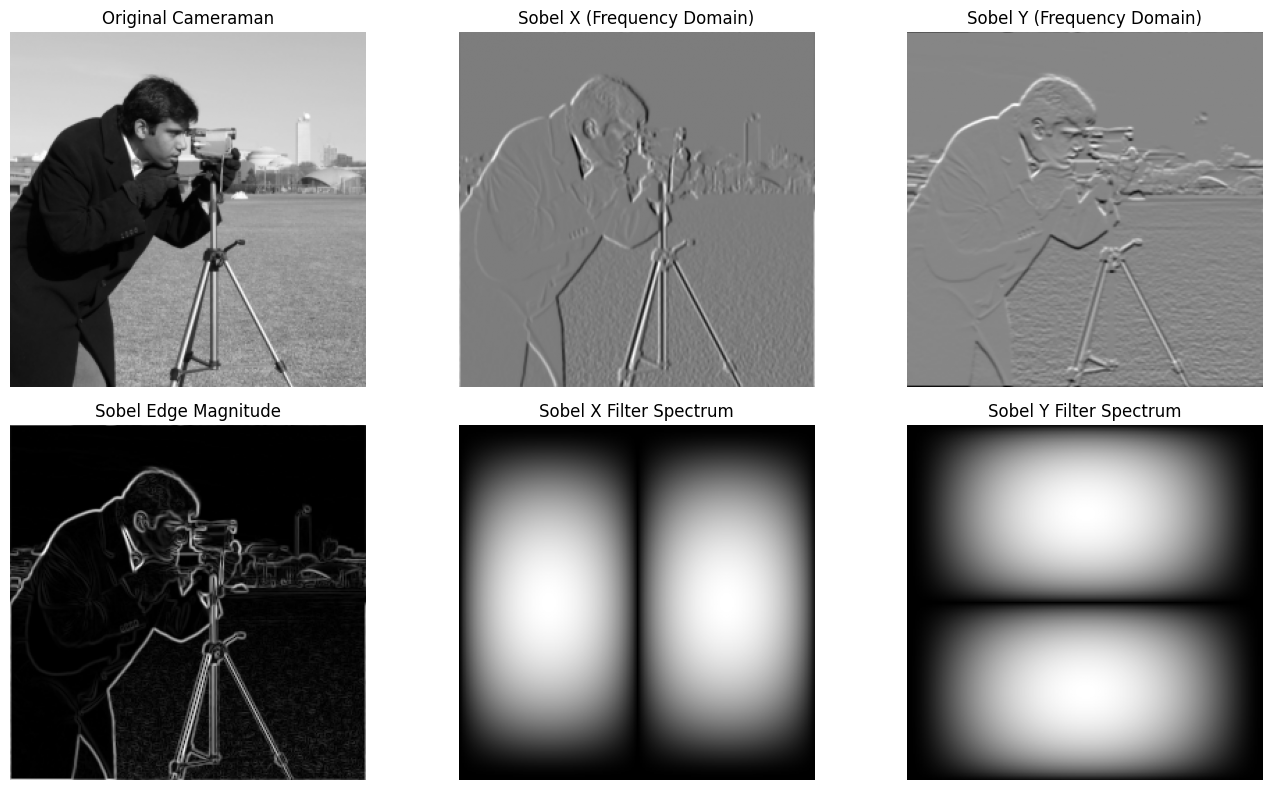

In [2]:
# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
           [ 0, 0, 0],
           [ 1, 2, 1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return np.fft.fft2(np.fft.ifftshift(padded)) # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = np.fft.fft2(image)

# FFT of centered Sobel filters (use the provided function)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
G_x = F * H_x
G_y = F * H_y
sobel_result_x = np.fft.ifft2(G_x).real
sobel_result_y = np.fft.ifft2(G_y).real
sobel_magnitude = np.hypot(sobel_result_x, sobel_result_y)

# Plot
plt.figure(figsize=(14, 8))
plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')
plt.subplot(2, 3, 2)
plt.imshow(sobel_result_x, cmap='gray')
plt.title('Sobel X (Frequency Domain)')
plt.axis('off')
plt.subplot(2, 3, 3)
plt.imshow(sobel_result_y, cmap='gray')
plt.title('Sobel Y (Frequency Domain)')
plt.axis('off')
plt.subplot(2, 3, 4)
plt.imshow(sobel_magnitude, cmap='gray')
plt.title('Sobel Edge Magnitude')
plt.axis('off')
plt.subplot(2, 3, 5)
plt.imshow(np.fft.fftshift(np.log1p(np.abs(H_x))), cmap='gray')
plt.title('Sobel X Filter Spectrum')
plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(np.fft.fftshift(np.log1p(np.abs(H_y))), cmap='gray')
plt.title('Sobel Y Filter Spectrum')
plt.axis('off')
plt.tight_layout()
plt.show()